# Assignment 16 - Bilal Ahmed

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("chinook.db")

print("Database connected successfully!")

Database connected successfully!


In [2]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

tables = pd.read_sql_query(query, conn)

display(tables)

,name
0,album
1,artist
2,customer
3,employee
4,genre
5,invoice
6,invoice_line
7,media_type
8,playlist
9,playlist_track


In [3]:
for table in tables["name"]:
    print("\nTable:", table)

    columns = pd.read_sql_query(
        f'PRAGMA table_info("{table}")',
        conn
    )

    print(columns[["name", "type"]])


Table: album
        name           type
0   album_id        INTEGER
1      title  NVARCHAR(160)
2  artist_id        INTEGER

Table: artist
        name           type
0  artist_id        INTEGER
1       name  NVARCHAR(120)

Table: customer
              name          type
0      customer_id       INTEGER
1       first_name  NVARCHAR(40)
2        last_name  NVARCHAR(20)
3          company  NVARCHAR(80)
4          address  NVARCHAR(70)
5             city  NVARCHAR(40)
6            state  NVARCHAR(40)
7          country  NVARCHAR(40)
8      postal_code  NVARCHAR(10)
9            phone  NVARCHAR(24)
10             fax  NVARCHAR(24)
11           email  NVARCHAR(60)
12  support_rep_id       INTEGER

Table: employee
           name          type
0   employee_id       INTEGER
1     last_name  NVARCHAR(20)
2    first_name  NVARCHAR(20)
3         title  NVARCHAR(30)
4    reports_to       INTEGER
5     birthdate      DATETIME
6     hire_date      DATETIME
7       address  NVARCHAR(70)
8        

## Q1. Write a query to list the top 10 genres with the highest number of tracks. (Show in bar plot)

,genre,track_count
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


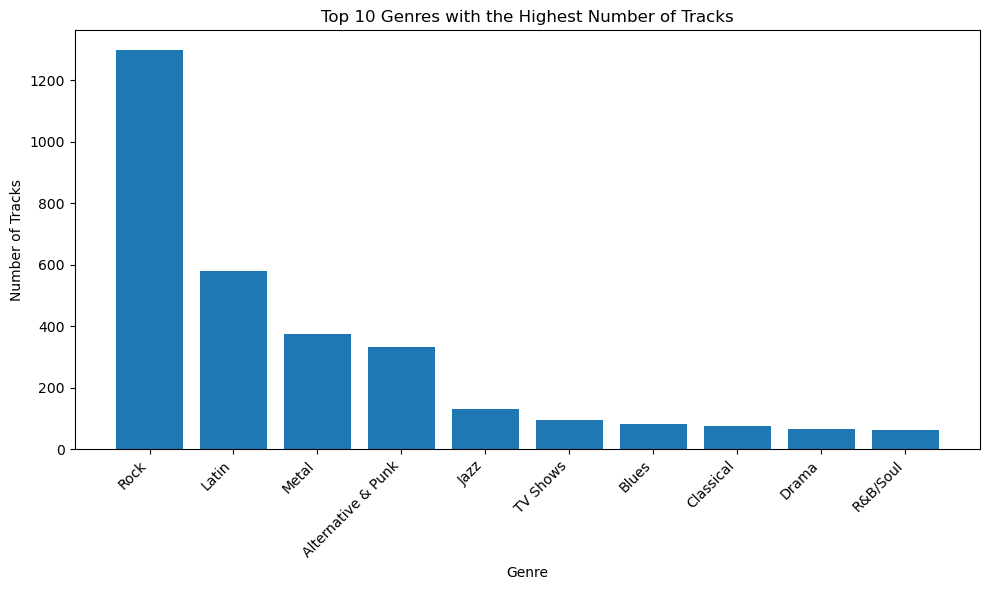

In [4]:
query1 = """
SELECT
    g.name AS genre,
    COUNT(t.track_id) AS track_count
FROM genre AS g
JOIN track AS t
    ON g.genre_id = t.genre_id
GROUP BY g.genre_id, g.name
ORDER BY track_count DESC
LIMIT 10;
"""

df1 = pd.read_sql_query(query1, conn)

display(df1)

plt.figure(figsize=(10, 6))

plt.bar(df1["genre"], df1["track_count"])

plt.title("Top 10 Genres with the Highest Number of Tracks")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Q2. Write a query to list the top 10 albums that contain the most tracks.

,album,artist,track_count
0,Greatest Hits,Lenny Kravitz,57
1,Minha Historia,Chico Buarque,34
2,Unplugged,Eric Clapton,30
3,"Lost, Season 3",Lost,26
4,"Lost, Season 1",Lost,25
5,"The Office, Season 3",The Office,25
6,My Way: The Best Of Frank Sinatra [Disc 1],Frank Sinatra,24
7,"Lost, Season 2",Lost,24
8,"Battlestar Galactica (Classic), Season 1",Battlestar Galactica (Classic),24
9,Afrociberdelia,Chico Science & Nação Zumbi,23


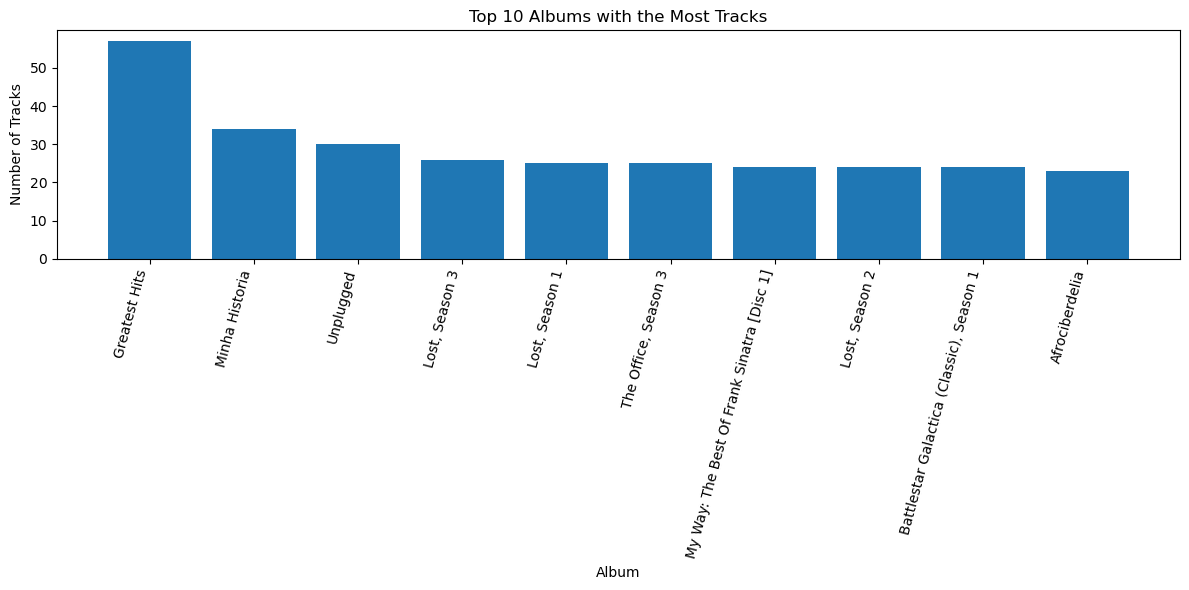

In [5]:

query2 = """
SELECT
    a.title AS album,
    ar.name AS artist,
    COUNT(t.track_id) AS track_count
FROM album AS a
JOIN track AS t
    ON a.album_id = t.album_id
JOIN artist AS ar
    ON a.artist_id = ar.artist_id
GROUP BY a.album_id, a.title, ar.name
ORDER BY track_count DESC
LIMIT 10;
"""

df2 = pd.read_sql_query(query2, conn)

display(df2)

plt.figure(figsize=(12, 6))

plt.bar(df2["album"], df2["track_count"])

plt.title("Top 10 Albums with the Most Tracks")
plt.xlabel("Album")
plt.ylabel("Number of Tracks")

plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


## Q3. Write a query to find the top 10 customers who spent the most money.

In [11]:
query = """
SELECT
    c.customer_id,
    c.first_name || ' ' || c.last_name AS customer_name,
    SUM(i.total) AS total_spent
FROM customer AS c
JOIN invoice AS i
    ON c.customer_id = i.customer_id
GROUP BY
    c.customer_id,
    c.first_name,
    c.last_name
ORDER BY total_spent DESC
LIMIT 10;
"""

df = pd.read_sql_query(query, conn)
display(df)

,customer_id,customer_name,total_spent
0,5,František Wichterlová,144.54
1,6,Helena Holý,128.70
2,46,Hugh O'Reilly,114.84
3,58,Manoj Pareek,111.87
4,1,Luís Gonçalves,108.90
5,13,Fernanda Ramos,106.92
6,34,João Fernandes,102.96
7,3,François Tremblay,99.99
8,42,Wyatt Girard,99.99
9,17,Jack Smith,98.01


## Q4. Write a query to find the top 5 artists who generated the highest revenue from track sales.

In [12]:
query = """
SELECT
    ar.artist_id,
    ar.name AS artist_name,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS total_revenue
FROM artist AS ar
JOIN album AS al
    ON ar.artist_id = al.artist_id
JOIN track AS t
    ON al.album_id = t.album_id
JOIN invoice_line AS il
    ON t.track_id = il.track_id
GROUP BY
    ar.artist_id,
    ar.name
ORDER BY total_revenue DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, conn)
display(df)

,artist_id,artist_name,total_revenue
0,51,Queen,190.08
1,94,Jimi Hendrix,185.13
2,110,Nirvana,128.70
3,127,Red Hot Chili Peppers,128.70
4,118,Pearl Jam,127.71


## Q5. Countries by Average Revenue per Invoice

In [13]:

query = """
SELECT
    billing_country AS country,
    ROUND(AVG(total), 2) AS average_revenue
FROM invoice
GROUP BY billing_country
ORDER BY average_revenue DESC;
"""

df = pd.read_sql_query(query, conn)
display(df)


,country,average_revenue
0,Czech Republic,9.11
1,Spain,8.91
2,Ireland,8.83
3,United Kingdom,8.77
4,India,8.72
5,Belgium,8.63
6,Germany,8.16
7,Australia,8.12
8,Norway,8.03
9,USA,7.94


## Q6. Write a query to find the media type with number of tracks.


In [14]:
query = """
SELECT
    m.name AS media_type,
    COUNT(t.track_id) AS number_of_tracks
FROM media_type AS m
JOIN track AS t
    ON m.media_type_id = t.media_type_id
GROUP BY
    m.media_type_id,
    m.name
ORDER BY number_of_tracks DESC;
"""

df = pd.read_sql_query(query, conn)
display(df)

,media_type,number_of_tracks
0,MPEG audio file,3034
1,Protected AAC audio file,237
2,Protected MPEG-4 video file,214
3,AAC audio file,11
4,Purchased AAC audio file,7


## Q7. Which artists have released tracks in more than one genre?

In [15]:

query = """
SELECT
    ar.artist_id,
    ar.name AS artist_name,
    COUNT(DISTINCT t.genre_id) AS number_of_genres
FROM artist AS ar
JOIN album AS al
    ON ar.artist_id = al.artist_id
JOIN track AS t
    ON al.album_id = t.album_id
WHERE t.genre_id IS NOT NULL
GROUP BY
    ar.artist_id,
    ar.name
HAVING COUNT(DISTINCT t.genre_id) > 1
ORDER BY number_of_genres DESC;
"""

df = pd.read_sql_query(query, conn)
display(df)

,artist_id,artist_name,number_of_genres
0,90,Iron Maiden,4
1,8,Audioslave,3
2,21,Various Artists,3
3,27,Gilberto Gil,3
4,92,Jamiroquai,3
5,100,Lenny Kravitz,3
6,147,Battlestar Galactica,3
7,6,Antônio Carlos Jobim,2
8,81,Eric Clapton,2
9,82,Faith No More,2


## Q8. Write a query to list the top 10 longest tracks by duration.

In [16]:

query = """
SELECT
    track_id,
    name AS track_name,
    milliseconds,
    ROUND(milliseconds / 60000.0, 2) AS duration_minutes
FROM track
ORDER BY milliseconds DESC
LIMIT 10;
"""

df = pd.read_sql_query(query, conn)
display(df)


,track_id,track_name,milliseconds,duration_minutes
0,2820,Occupation / Precipice,5286953,88.12
1,3224,Through a Looking Glass,5088838,84.81
2,3244,"Greetings from Earth, Pt. 1",2960293,49.34
3,3242,The Man With Nine Lives,2956998,49.28
4,3227,"Battlestar Galactica, Pt. 2",2956081,49.27
5,3226,"Battlestar Galactica, Pt. 1",2952702,49.21
6,3243,Murder On the Rising Star,2935894,48.93
7,3228,"Battlestar Galactica, Pt. 3",2927802,48.80
8,3248,Take the Celestra,2927677,48.79
9,3239,Fire In Space,2926593,48.78


## Q9. Top 5 Revenue Share percentage by Artist (Pie Chart)

In [17]:
query = """
SELECT
    ar.name AS artist_name,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS total_revenue
FROM artist AS ar
JOIN album AS al
    ON ar.artist_id = al.artist_id
JOIN track AS t
    ON al.album_id = t.album_id
JOIN invoice_line AS il
    ON t.track_id = il.track_id
GROUP BY ar.artist_id, ar.name
ORDER BY total_revenue DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, conn)
display(df)

,artist_name,total_revenue
0,Queen,190.08
1,Jimi Hendrix,185.13
2,Nirvana,128.70
3,Red Hot Chili Peppers,128.70
4,Pearl Jam,127.71


In [18]:

df["Revenue_Share_Percentage"] = (
    df["total_revenue"] / df["total_revenue"].sum()
) * 100

df["Revenue_Share_Percentage"] = (
    df["Revenue_Share_Percentage"].round(2)
)

display(df)


,artist_name,total_revenue,Revenue_Share_Percentage
0,Queen,190.08,25.00
1,Jimi Hendrix,185.13,24.35
2,Nirvana,128.70,16.93
3,Red Hot Chili Peppers,128.70,16.93
4,Pearl Jam,127.71,16.80


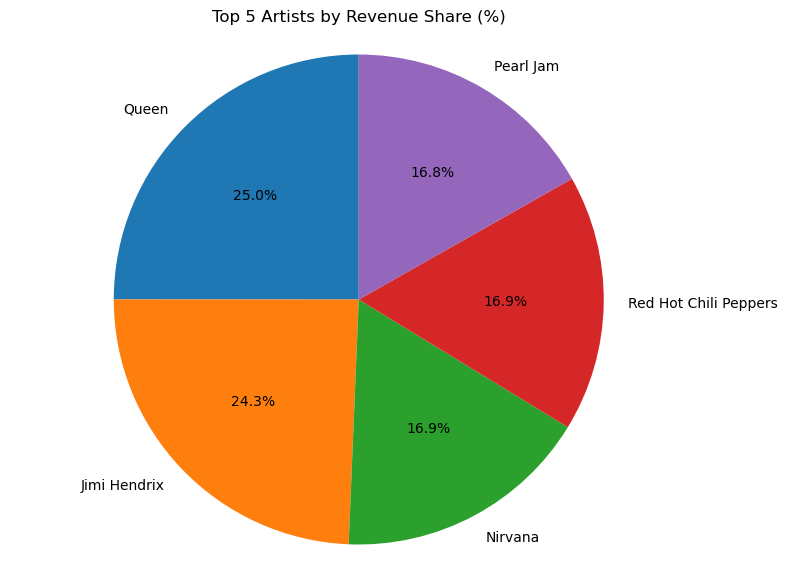

In [19]:
plt.figure(figsize=(9, 7))

plt.pie(
    df["Revenue_Share_Percentage"],
    labels=df["artist_name"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 Artists by Revenue Share (%)")
plt.axis("equal")
plt.show()

## Q10. Revenue by Genre (Rock, Latin, Metal) in Each Country (Stacked Column Chart)

In [20]:

query = """
SELECT
    i.billing_country AS country,
    g.name AS genre,
    ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
FROM invoice AS i
JOIN invoice_line AS il
    ON i.invoice_id = il.invoice_id
JOIN track AS t
    ON il.track_id = t.track_id
JOIN genre AS g
    ON t.genre_id = g.genre_id
WHERE g.name IN ('Rock', 'Latin', 'Metal')
GROUP BY
    i.billing_country,
    g.name
ORDER BY
    i.billing_country,
    g.name;
"""

df = pd.read_sql_query(query, conn)
display(df)


,country,genre,revenue
0,Argentina,Latin,1.98
1,Argentina,Metal,1.98
2,Argentina,Rock,10.89
3,Australia,Latin,1.98
4,Australia,Metal,13.86
...,...,...,...
65,USA,Metal,122.76
66,USA,Rock,555.39
67,United Kingdom,Latin,6.93
68,United Kingdom,Metal,30.69


In [21]:

pivot_df = df.pivot(
    index="country",
    columns="genre",
    values="revenue"
).fillna(0)

display(pivot_df)


genre,Latin,Metal,Rock
country,,,
Argentina,1.98,1.98,10.89
Australia,1.98,13.86,33.66
Austria,0.99,6.93,39.60
Belgium,1.98,18.81,25.74
Brazil,12.87,72.27,202.95
Canada,12.87,71.28,329.67
Chile,3.96,10.89,60.39
Czech Republic,20.79,22.77,141.57
Denmark,0.00,4.95,23.76


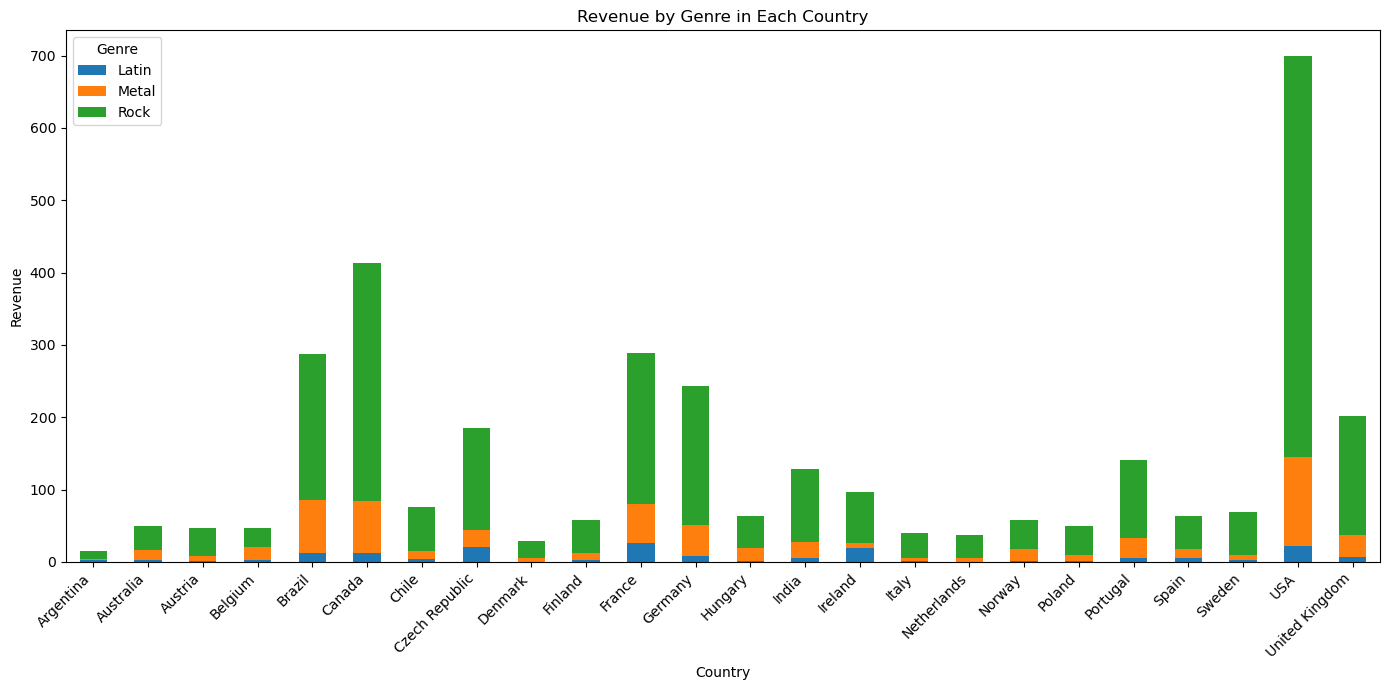

In [22]:
pivot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Revenue by Genre in Each Country")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Genre")
plt.tight_layout()
plt.show()